In [1]:
%load_ext autoreload
%autoreload 2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
from quantmgmt.data.prices import download_prices
from quantmgmt.risk.returns import to_returns

SECTORES = ["XLK","XLF","XLE","XLV","XLI","XLY","XLP","XLU","XLB","XLRE"]
TICKERS = SECTORES + ["SPY"]
INICIO, FIN = "2009-12-01", "2026-10-01"   # FIN excluido: último mes completo = sep-2026

precios_mes = download_prices(TICKERS, start=INICIO, end=FIN).resample("ME").last()
rent = to_returns(precios_mes)
rent_10 = rent.loc["2015-11-30":, SECTORES]
rent_9 = rent[SECTORES].drop(columns="XLRE")
print(rent.index[-1].date(), rent_10.shape, rent_9.shape, rent_10.isna().sum().sum())

2026-09-30 (131, 10) (201, 9) 0


In [3]:
from quantmgmt.data.factors import download_ff_factors
factores = download_ff_factors(end="2026-09-30")
factores.tail()

,Mkt-RF,SMB,HML,RMW,CMA,RF,Mom
Date,,,,,,,
2026-04-30,0.0995,0.0046,-0.0137,-0.0415,-0.0380,0.0029,0.0951
2026-05-31,0.0491,-0.0265,-0.0231,-0.0816,-0.0146,0.0031,0.0139
2026-06-30,-0.0107,0.0436,0.0358,-0.0507,0.0345,0.0029,0.0462
2026-07-31,-0.0061,-0.0009,0.0211,0.1107,0.0226,0.0033,-0.1220
2026-08-31,0.0256,-0.0053,-0.0354,-0.0408,-0.0201,0.0029,-0.0570


In [4]:
from quantmgmt.optimizers.mean_variance import (
    estimate_inputs, portfolio_stats, min_variance, max_sharpe, efficient_frontier, target_volatility,
)
mu, sigma = estimate_inputs(rent_10)
rf = factores["RF"].reindex(rent_10.index).mean() * 12   # RF medio anual del periodo
w_mv = min_variance(sigma)
w_mv.round(3).sort_values(ascending=False)

XLP     0.402
XLV     0.276
XLU     0.223
XLK     0.091
XLF     0.007
XLE     0.000
XLY     0.000
XLI     0.000
XLB     0.000
XLRE    0.000
Name: min_variance, dtype: float64

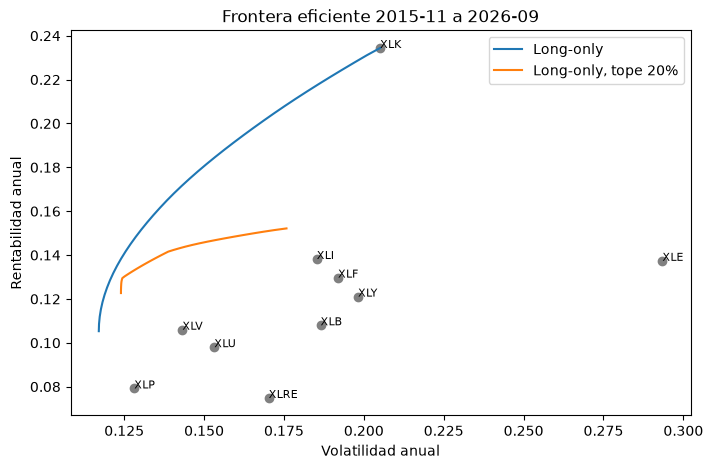

count    40.000000
mean      3.925000
std       0.888314
min       1.000000
25%       3.750000
50%       4.000000
75%       4.250000
max       5.000000
dtype: float64
count    40.000000
mean      6.450000
std       0.552384
min       5.000000
25%       6.000000
50%       6.000000
75%       7.000000
max       7.000000
dtype: float64


In [5]:
import matplotlib.pyplot as plt
from quantmgmt.optimizers.mean_variance import efficient_frontier

fr_libre = efficient_frontier(mu, sigma, n_points=40)
fr_20 = efficient_frontier(mu, sigma, n_points=40, max_weight=0.20)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(fr_libre.vol, fr_libre.ret, label="Long-only")
ax.plot(fr_20.vol, fr_20.ret, label="Long-only, tope 20%")
ax.scatter(np.sqrt(np.diag(sigma)), mu, c="grey")
for t in mu.index:
    ax.annotate(t, (np.sqrt(sigma.loc[t, t]), mu[t]), fontsize=8)
ax.set(xlabel="Volatilidad anual", ylabel="Rentabilidad anual", title="Frontera eficiente 2015-11 a 2026-09")
ax.legend(); plt.show()

# concentración: cuántos activos tienen un peso de más del 1% en cada punto
SECT = list(mu.index)
print((fr_libre[SECT] > 0.01).sum(axis=1).describe())
print((fr_20[SECT] > 0.01).sum(axis=1).describe())

**Concentración.** Sin tope, la frontera se apoya en unos 4 sectores de media y en el extremo de máxima rentabilidad en uno solo. Con el tope del 20 % nunca baja de 5 sectores con peso relevante: la restricción obliga a diversificar a cambio de renunciar a la parte más alta de la curva.

## 4. Referencias: máximo Sharpe frente a la equiponderada y a SPY

Misma muestra que la frontera (nov-2015 a sep-2026, los 10 sectores). Las carteras se rebalancean cada mes a pesos fijos y se miden con las funciones de la Práctica 1 (`quantmgmt.risk`) con `periods_per_year=12`.

In [6]:
from quantmgmt import risk

w_ms = max_sharpe(mu, sigma, rf=rf)
w_ms20 = max_sharpe(mu, sigma, rf=rf, max_weight=0.20)
w_eq = pd.Series(1 / len(SECTORES), index=SECTORES)

pd.DataFrame({"Máx. Sharpe": w_ms, "Máx. Sharpe (tope 20%)": w_ms20, "Equiponderada": w_eq}).round(3)

,Máx. Sharpe,Máx. Sharpe (tope 20%),Equiponderada
XLK,0.704,0.200,0.1
XLF,0.000,0.173,0.1
XLE,0.047,0.029,0.1
XLV,0.042,0.200,0.1
XLI,0.000,0.069,0.1
XLY,0.000,0.000,0.1
XLP,0.000,0.129,0.1
XLU,0.207,0.200,0.1
XLB,0.000,0.000,0.1
XLRE,0.000,0.000,0.1


In [7]:
def tabla_metricas(r, rf_mes):
    """Métricas de la Práctica 1 con datos mensuales."""
    return pd.DataFrame({
        "CAGR": risk.cagr(r, 12),
        "Volatilidad": risk.annualized_volatility(r, 12),
        "Sharpe": risk.sharpe_ratio(r, 12, rf_mes),
        "Sortino": risk.sortino_ratio(r, 12, rf_mes),
        "Máx. drawdown": risk.max_drawdown(r),
        "Calmar": risk.calmar_ratio(r, 12),
        "VaR 95% mensual": risk.var_historical(r),
        "CVaR 95% mensual": risk.cvar_historical(r),
    })

carteras = pd.DataFrame({
    "Máx. Sharpe": rent_10 @ w_ms,
    "Máx. Sharpe (tope 20%)": rent_10 @ w_ms20,
    "Equiponderada": rent_10 @ w_eq,
    "SPY": rent.loc[rent_10.index, "SPY"],
})
rf_mes = factores["RF"].reindex(rent_10.index).mean()
tabla_metricas(carteras, rf_mes).round(3)

,CAGR,Volatilidad,Sharpe,Sortino,Máx. drawdown,Calmar,VaR 95% mensual,CVaR 95% mensual
Máx. Sharpe,0.199,0.164,1.067,1.854,0.232,0.859,0.065,0.088
Máx. Sharpe (tope 20%),0.133,0.129,0.871,1.362,0.190,0.699,0.052,0.078
Equiponderada,0.118,0.144,0.702,1.076,0.232,0.511,0.057,0.089
SPY,0.145,0.149,0.842,1.333,0.239,0.606,0.066,0.089


Dentro de la muestra, el máximo Sharpe gana por construcción: se ha elegido mirando estos mismos datos. Sin tope pone la mayor parte en tecnología (XLK), el sector que mejor lo ha hecho. Esta tabla no demuestra nada; la prueba de verdad es el apartado 5.

### CAPM: la recta del mercado de valores (SML)

Beta de cada sector contra SPY con excesos mensuales sobre el tipo libre de riesgo y regresión de la rentabilidad media sobre la beta. Según el CAPM, la constante debería ser 0 y la pendiente, igual a la prima de mercado (exceso medio de SPY).

        coef      t
const  0.007  0.168
beta   0.110  2.627
R²: 0.46 | teoría: constante 0 y pendiente 12.73%


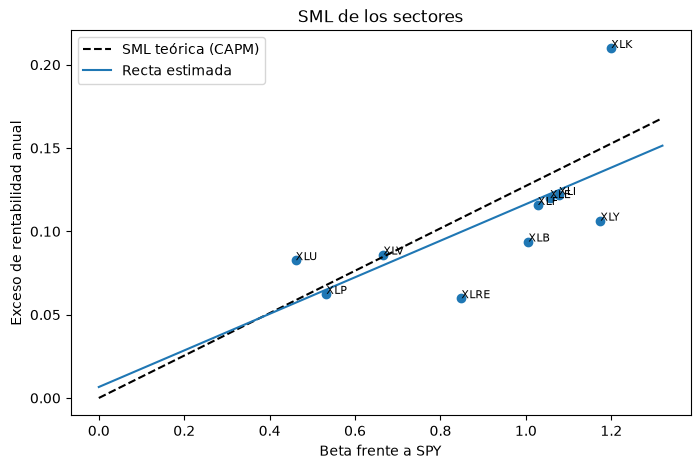

In [8]:
import statsmodels.api as sm

exceso = rent[TICKERS].sub(factores["RF"], axis=0).loc[rent_10.index].dropna()
betas = exceso[SECTORES].apply(lambda s: s.cov(exceso["SPY"]) / exceso["SPY"].var()).rename("beta")
exceso_medio = exceso[SECTORES].mean() * 12
prima_mercado = exceso["SPY"].mean() * 12

sml = sm.OLS(exceso_medio, sm.add_constant(betas)).fit()
print(pd.DataFrame({"coef": sml.params, "t": sml.tvalues}).round(3))
print(f"R²: {sml.rsquared:.2f} | teoría: constante 0 y pendiente {prima_mercado:.2%}")

x = np.linspace(0, betas.max() * 1.1, 50)
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(betas, exceso_medio)
for t in SECTORES:
    ax.annotate(t, (betas[t], exceso_medio[t]), fontsize=8)
ax.plot(x, prima_mercado * x, "k--", label="SML teórica (CAPM)")
ax.plot(x, sml.params["const"] + sml.params["beta"] * x, label="Recta estimada")
ax.set(xlabel="Beta frente a SPY", ylabel="Exceso de rentabilidad anual", title="SML de los sectores")
ax.legend(); plt.show()

**¿Se cumple?** Solo a grandes rasgos. La constante es prácticamente cero y la pendiente es positiva y significativa: a más beta, más rentabilidad. Pero la recta estimada es algo más plana que la teórica y la beta explica menos de la mitad de las diferencias entre sectores (R² ≈ 0,46). XLK queda muy por encima de la recta (lo que el CAPM llamaría alfa) y XLRE o XLY, por debajo. Son 10 puntos y un solo periodo, así que la conclusión es débil; el apartado de factores (Parte B) intenta explicar lo que la beta no explica.

## 5. Fuera de muestra: estimar con 2010-2017 y evaluar de 2019 a hoy

XLRE no cotiza antes de octubre de 2015, así que aquí se usan los otros 9 sectores. 2018 queda fuera como separación entre estimación y evaluación. Los pesos se fijan con los datos de 2010-2017 y no se vuelven a tocar.

In [9]:
dentro = rent_9.loc["2010":"2017"]
fuera = rent_9.loc["2019":]
mu_in, sigma_in = estimate_inputs(dentro)
rf_in = factores["RF"].loc["2010":"2017"].mean() * 12

pesos_in = {
    "Máx. Sharpe": max_sharpe(mu_in, sigma_in, rf=rf_in),
    "Máx. Sharpe (tope 20%)": max_sharpe(mu_in, sigma_in, rf=rf_in, max_weight=0.20),
    "Mín. varianza": min_variance(sigma_in),
    "Equiponderada": pd.Series(1 / dentro.shape[1], index=dentro.columns),
}
pd.DataFrame(pesos_in).round(3)

,Máx. Sharpe,Máx. Sharpe (tope 20%),Mín. varianza,Equiponderada
XLK,0.000,0.171,0.028,0.111
XLF,0.000,0.000,0.028,0.111
XLE,0.000,0.000,0.048,0.111
XLV,0.285,0.200,0.250,0.111
XLI,0.000,0.029,0.000,0.111
XLY,0.334,0.200,0.000,0.111
XLP,0.099,0.200,0.339,0.111
XLU,0.282,0.200,0.306,0.111
XLB,0.000,0.000,0.000,0.111


In [10]:
# Lo que esperábamos con la estimación frente a lo que llegó después
fuera_carteras = pd.DataFrame({k: fuera @ w for k, w in pesos_in.items()})
fuera_carteras["SPY"] = rent.loc[fuera.index, "SPY"]
rf_fuera = factores["RF"].reindex(fuera.index).mean()

esperado = pd.DataFrame(
    {k: portfolio_stats(w.to_numpy(), mu_in, sigma_in, rf_in) for k, w in pesos_in.items()}
).T
real = pd.DataFrame({
    "ret": risk.annualized_return(fuera_carteras, 12),
    "vol": risk.annualized_volatility(fuera_carteras, 12),
    "sharpe": risk.sharpe_ratio(fuera_carteras, 12, rf_fuera),
})
pd.concat({"Esperado (2010-2017)": esperado, "Real (2019-hoy)": real}, axis=1).round(3)

Esperado (2010-2017)               Real (2019-hoy)  \
                                        ret    vol sharpe             ret   
Máx. Sharpe                           0.145  0.097  1.471           0.114   
Máx. Sharpe (tope 20%)                0.144  0.098  1.445           0.140   
Mín. varianza                         0.126  0.092  1.354           0.111   
Equiponderada                         0.133  0.117  1.131           0.149   
SPY                                     NaN    NaN    NaN           0.173   

                                      
                          vol sharpe  
Máx. Sharpe             0.141  0.622  
Máx. Sharpe (tope 20%)  0.140  0.805  
Mín. varianza           0.129  0.657  
Equiponderada           0.159  0.768  
SPY                     0.164  0.893

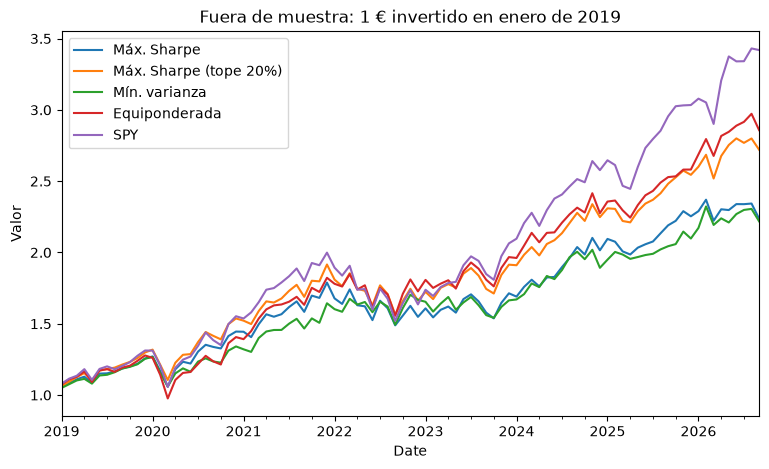

,CAGR,Volatilidad,Sharpe,Sortino,Máx. drawdown,Calmar,VaR 95% mensual,CVaR 95% mensual
Máx. Sharpe,0.109,0.141,0.622,0.972,0.168,0.653,0.062,0.075
Máx. Sharpe (tope 20%),0.138,0.140,0.805,1.284,0.183,0.753,0.059,0.075
Mín. varianza,0.108,0.129,0.657,1.032,0.164,0.662,0.054,0.074
Equiponderada,0.145,0.159,0.768,1.210,0.236,0.615,0.060,0.096
SPY,0.172,0.164,0.893,1.443,0.239,0.719,0.070,0.093


In [11]:
(1 + fuera_carteras).cumprod().plot(
    figsize=(9, 5), title="Fuera de muestra: 1 € invertido en enero de 2019", ylabel="Valor"
)
plt.show()
tabla_metricas(fuera_carteras, rf_fuera).round(3)

**Lo que esperábamos frente a lo que llegó.**

- El máximo Sharpe prometía un Sharpe cercano a 1,5 y dio alrededor de 0,6: es la cartera que más se ha alejado de lo esperado. Con los datos de 2010-2017 apostó por consumo discrecional, salud y utilities y dejó fuera la tecnología, justo el sector que más ha subido desde 2019.
- La volatilidad también se quedó corta: todas las carteras han sido bastante más volátiles de lo estimado (COVID en 2020, inflación y subidas de tipos en 2022).
- El tope del 20 % mejora el resultado real del máximo Sharpe: al obligar a diversificar, el error de estimación pesa menos.
- Ninguna cartera optimizada bate a SPY ni, en Sharpe, de forma clara a la equiponderada.

Es el problema conocido de Markowitz: el optimizador se fía de rentabilidades medias estimadas con mucho ruido y concentra la cartera en los ganadores del pasado. Las restricciones lo suavizan; la Práctica 3 (Black-Litterman y HRP) lo ataca directamente.

# Parte B: modelos multifactoriales

Regresión del exceso de rentabilidad mensual (sobre `RF`) de cada cartera contra los factores de Ken French con `run_factor_regression` (`quantmgmt/analytics/factors.py`). El alfa está anualizada y los t-estadísticos usan errores de Newey-West, como en el notebook de *Buffett's Alpha*. Un |t| mayor que 1,96 indica alfa significativa al 5 %.

- **CAPM:** mercado.
- **FF3:** + tamaño (SMB) y valor (HML).
- **Carhart 4:** FF3 + momentum (Mom).
- **FF5:** FF3 + rentabilidad (RMW) e inversión (CMA).

Universo: los 10 sectores (desde 2010; XLRE desde nov-2015) y las dos carteras de la parte A (máximo Sharpe y equiponderada, desde nov-2015). Los factores de French llegan hasta agosto de 2026.

In [12]:
from quantmgmt.analytics import MODELS, rolling_betas, run_factor_regression

universo = rent[SECTORES].join(carteras[["Máx. Sharpe", "Equiponderada"]])
resultados = {m: run_factor_regression(universo, factores, model=m) for m in MODELS}

nombres = {"alpha": "Alfa anual", "t_alpha": "t(alfa)", "r2_adj": "R² aj."}
tabla_alfas = pd.concat(
    {m: r[list(nombres)].rename(columns=nombres) for m, r in resultados.items()}, axis=1
)
tabla_alfas.round(3)

CAPM                       FF3                  Carhart4  \
              Alfa anual t(alfa) R² aj. Alfa anual t(alfa) R² aj. Alfa anual   
XLK                0.041   1.858  0.763      0.026   1.551  0.843      0.024   
XLF               -0.021  -0.805  0.720     -0.015  -0.816  0.863     -0.011   
XLE               -0.041  -0.600  0.370     -0.024  -0.589  0.609     -0.011   
XLV                0.029   1.339  0.505      0.026   1.181  0.503      0.024   
XLI               -0.009  -0.533  0.806     -0.003  -0.218  0.842     -0.006   
XLY               -0.008  -0.449  0.826     -0.005  -0.319  0.844     -0.003   
XLP                0.023   1.051  0.398      0.011   0.547  0.467      0.008   
XLU                0.041   1.458  0.148      0.032   1.109  0.178      0.022   
XLB               -0.044  -1.908  0.697     -0.040  -1.854  0.737     -0.035   
XLRE              -0.042  -1.236  0.532     -0.041  -1.218  0.527     -0.041   
Máx. Sharpe        0.051   3.019  0.837      0.041   2.591  0.886      0.037   
Equiponderada     -0.005  -0.251  0.876     -0.007  -0.606  0.918     -0.006   

                                    FF5                 
              t(alfa) R² aj. Alfa anual t(alfa) R² aj.  
XLK             1.468  0.843      0.033   1.687  0.852  
XLF            -0.635  0.864     -0.009  -0.519  0.870  
XLE            -0.255  0.623     -0.034  -0.836  0.617  
XLV             1.080  0.501      0.019   0.856  0.531  
XLI            -0.408  0.843     -0.009  -0.669  0.850  
XLY            -0.215  0.844     -0.006  -0.347  0.851  
XLP             0.414  0.468     -0.006  -0.359  0.625  
XLU             0.752  0.203      0.020   0.733  0.224  
XLB            -1.598  0.741     -0.049  -2.435  0.755  
XLRE           -1.227  0.523     -0.047  -1.487  0.557  
Máx. Sharpe     2.530  0.890      0.042   2.601  0.888  
Equiponderada  -0.531  0.918     -0.011  -1.147  0.936

In [13]:
# Cuántas alfas son significativas al 5 % y cuánto explica cada modelo de media
pd.DataFrame({
    "Alfas significativas (5 %)": {m: int((r["t_alpha"].abs() > 1.96).sum()) for m, r in resultados.items()},
    "R² aj. medio (10 sectores)": {m: r.loc[SECTORES, "r2_adj"].mean() for m, r in resultados.items()},
}).round(3)

,Alfas significativas (5 %),R² aj. medio (10 sectores)
CAPM,1,0.577
FF3,1,0.641
Carhart4,1,0.645
FF5,2,0.673


In [14]:
# Exposiciones del modelo de cinco factores
resultados["FF5"].filter(like="beta_").round(2)

,beta_Mkt-RF,beta_SMB,beta_HML,beta_RMW,beta_CMA
XLK,1.16,-0.41,-0.21,-0.20,-0.19
XLF,1.01,-0.01,0.75,-0.09,-0.28
XLE,1.06,0.31,0.89,0.21,0.41
XLV,0.70,-0.02,-0.19,0.06,0.43
XLI,1.06,0.18,0.16,0.18,0.19
XLY,1.08,0.18,-0.18,0.18,-0.21
XLP,0.64,-0.20,-0.13,0.43,0.61
XLU,0.47,-0.19,-0.06,0.30,0.40
XLB,1.07,0.15,0.16,0.27,0.29
XLRE,0.80,0.17,-0.12,0.33,0.24


**Lectura de la tabla.**

- **Sectores:** ninguno tiene alfa positiva significativa con ningún modelo. Lo que parecía alfa en el CAPM se reparte entre factores al añadirlos:
  - XLK pasa de un 4,1 % (t ≈ 1,9) a un 2,6 % en FF3, porque carga en negativo en tamaño y valor: grandes empresas growth.
  - XLP y XLU tienen alfa CAPM positiva que en FF5 desaparece: son empresas rentables y conservadoras (betas RMW y CMA positivas).
  - El único alfa significativo entre los sectores es negativo: XLB en FF5 rinde menos de lo que sus factores predicen.
- **Qué aporta FF5:** el R² medio de los sectores sube de ≈ 0,58 (CAPM) a ≈ 0,67 (FF5). La mejora se concentra en los defensivos (XLP pasa de 0,47 a 0,63), justo los que explican RMW y CMA. El momentum de Carhart apenas añade nada en este universo.
- **Cartera equiponderada:** alfa ≈ 0 y R² de 0,94: es pura exposición a factores.
- **Cartera de máximo Sharpe:** mantiene un alfa del 4 % con t > 2,5 incluso en FF5. Pero sus pesos se eligieron mirando estos mismos datos (70 % XLK). Es un alfa construido a posteriori, no habilidad: en la parte A, fuera de muestra, fue la peor de las carteras optimizadas.

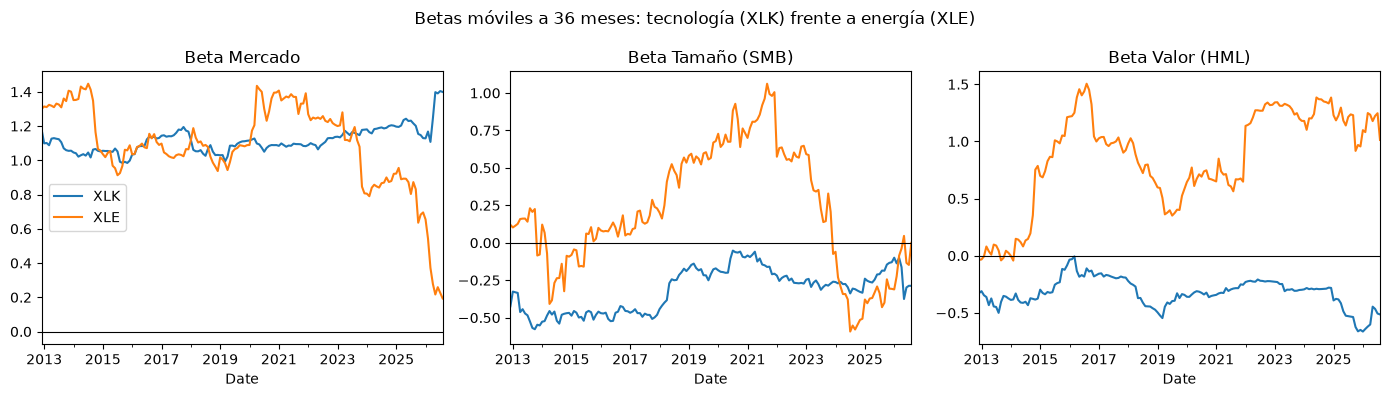

In [15]:
# Betas móviles a 36 meses (FF3) de dos sectores con exposiciones opuestas
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharex=True)
for sector in ["XLK", "XLE"]:
    betas_moviles = rolling_betas(rent[sector], factores, model="FF3", window=36)
    for ax, factor in zip(axes, ["Mkt-RF", "SMB", "HML"]):
        betas_moviles[factor].plot(ax=ax, label=sector)
for ax, titulo in zip(axes, ["Mercado", "Tamaño (SMB)", "Valor (HML)"]):
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title(f"Beta {titulo}")
axes[0].legend()
fig.suptitle("Betas móviles a 36 meses: tecnología (XLK) frente a energía (XLE)")
plt.tight_layout(); plt.show()

**Betas móviles.** XLK es estable: beta de mercado algo por encima de 1 y betas de tamaño y valor siempre negativas (grandes compañías growth). XLE es lo contrario, una apuesta clara por valor (beta HML cercana a 0,9 de media), y además muy inestable: su beta de mercado se mueve entre 0,2 y 1,45 según la ventana. Una regresión de toda la muestra da una foto media que esconde estos cambios.